In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt

plt.style.use("bmh")

In [2]:
# Read the economic summary dataset

df = pd.read_csv("../data/processed/pakistan_city_economic_summary.csv")

df.head()

,District,Establishments,Workforce
0,Lahore,429891,2014908
1,Karachi (4 districts),341682,1567422
2,Peshawar,116022,587659
3,Quetta,84231,438882
4,Islamabad,86154,621514


In [3]:
# Check the basic information of the dataset

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   District        5 non-null      str  
 1   Establishments  5 non-null      int64
 2   Workforce       5 non-null      int64
dtypes: int64(2), str(1)
memory usage: 252.0 bytes


In [4]:
# Compare the total number of establishments by location

df = df.sort_values(
    "Establishments",
    ascending=False
)

df

,District,Establishments,Workforce
0,Lahore,429891,2014908
1,Karachi (4 districts),341682,1567422
2,Peshawar,116022,587659
4,Islamabad,86154,621514
3,Quetta,84231,438882


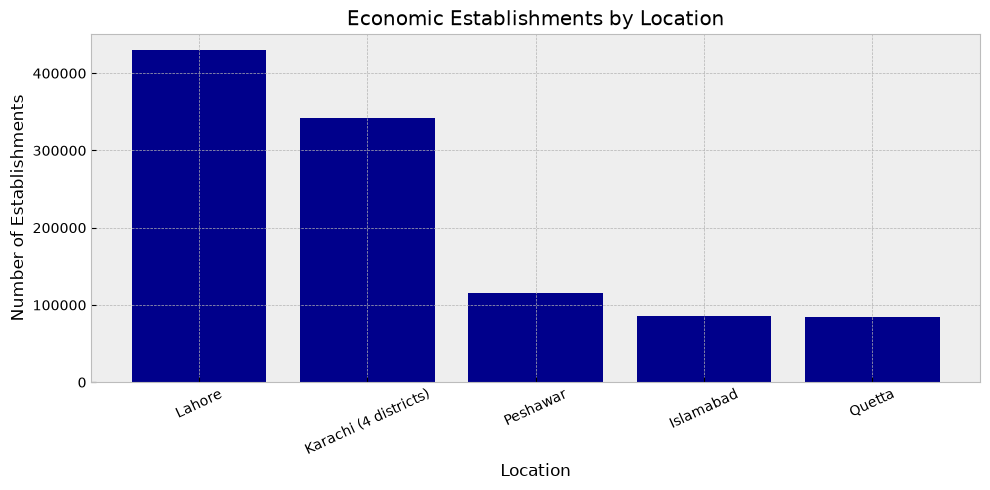

In [5]:
# Visualization of economic establishments by location

plt.figure(figsize=(10, 5))

plt.bar(
    df["District"],
    df["Establishments"],
    color="darkblue"
)

plt.title("Economic Establishments by Location")
plt.xlabel("Location")
plt.ylabel("Number of Establishments")
plt.xticks(rotation=25)

plt.tight_layout()
plt.show()

In [6]:
# Compare the total workforce by location

df = df.sort_values(
    "Workforce",
    ascending=False
)

df

,District,Establishments,Workforce
0,Lahore,429891,2014908
1,Karachi (4 districts),341682,1567422
4,Islamabad,86154,621514
2,Peshawar,116022,587659
3,Quetta,84231,438882


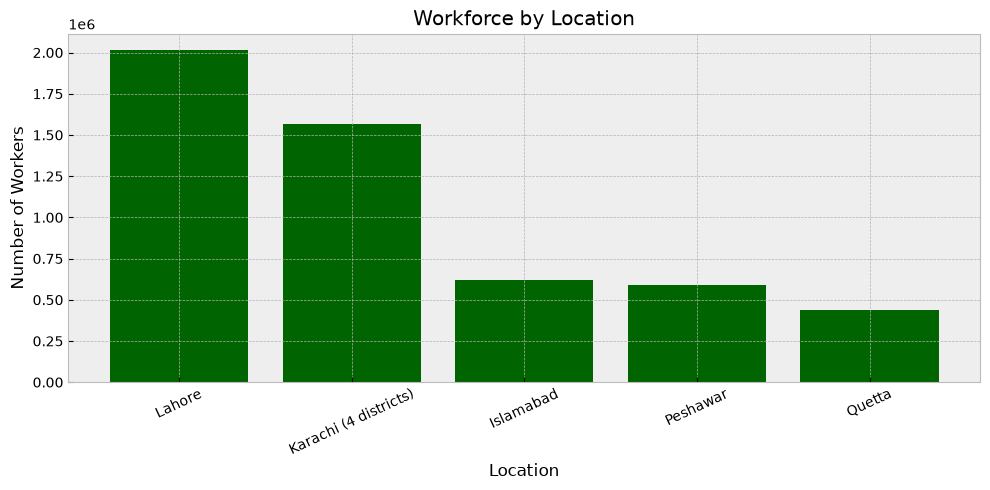

In [7]:
# Visualization of workforce by location

plt.figure(figsize=(10, 5))

plt.bar(
    df["District"],
    df["Workforce"],
    color="darkgreen"
)

plt.title("Workforce by Location")
plt.xlabel("Location")
plt.ylabel("Number of Workers")
plt.xticks(rotation=25)

plt.tight_layout()
plt.show()

In [8]:
# Read the economic categories dataset

df = pd.read_csv("../data/processed/pakistan_economic_categories.csv")

df.head()

,District,Sr_No,Description,PSIC_Codes,Establishments,Workforce,City
0,Lahore,1,"Agriculture, forestry and fishing",01-03,13780,29161,Lahore
1,Lahore,2,Mining and quarrying,05-09,12,63,Lahore
2,Lahore,3,Manufacturing,10-33,46703,296298,Lahore
3,Lahore,4,"Electricity, gas, steam and air conditioning s...",35,52,2432,Lahore
4,Lahore,5,"Water supply; sewerage, waste management and r...",36-39,1331,5442,Lahore


In [9]:
# Check the columns and data types of the dataset

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   District        167 non-null    str  
 1   Sr_No           167 non-null    int64
 2   Description     167 non-null    str  
 3   PSIC_Codes      159 non-null    str  
 4   Establishments  167 non-null    int64
 5   Workforce       167 non-null    int64
 6   City            167 non-null    str  
dtypes: int64(3), str(4)
memory usage: 9.3 KB


In [10]:
# Check missing values in the economic categories dataset

df.isna().sum()

District          0
Sr_No             0
Description       0
PSIC_Codes        8
Establishments    0
Workforce         0
City              0
dtype: int64

In [11]:
# Calculate the total workforce in each economic sector by city

large_sector_workforce = df.groupby(
    ["City", "Description"],
    as_index=False
)["Workforce"].sum()

large_sector_workforce.head()

,City,Description,Workforce
0,Islamabad,Accommodation and food service activities,47852
1,Islamabad,Activities of extraterritorial organizations a...,0
2,Islamabad,Administrative and support service activities,18827
3,Islamabad,"Agriculture, forestry and fishing",38007
4,Islamabad,"Arts, entertainment and recreation",3346


In [12]:
# Find the sector with the highest workforce in each city

idx = large_sector_workforce.groupby("City")["Workforce"].idxmax()

largest_workforce_sector = large_sector_workforce.loc[
    idx,
    ["City", "Description", "Workforce"]
].sort_values("City")

largest_workforce_sector

,City,Description,Workforce
20,Islamabad,Wholesale and retail trade; repair of motor ve...,149868
40,Karachi,Wholesale and retail trade; repair of motor ve...,581531
62,Lahore,Wholesale and retail trade; repair of motor ve...,748260
83,Peshawar,Wholesale and retail trade; repair of motor ve...,169275
89,Quetta,Education,135234


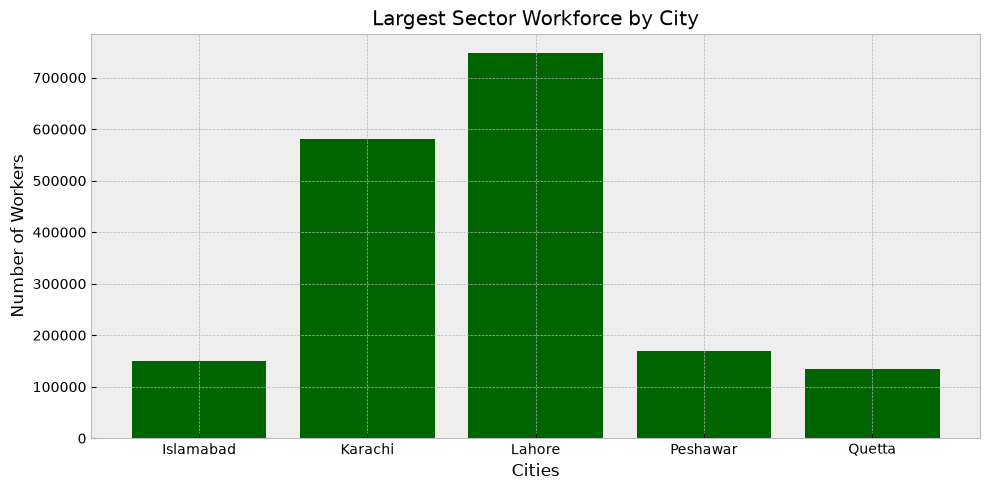

In [13]:
# Visualization of the largest workforce sector in each city

plt.figure(figsize=(10, 5))

plt.bar(
    largest_workforce_sector["City"],
    largest_workforce_sector["Workforce"],
    color="darkgreen"
)

plt.title("Largest Sector Workforce by City")
plt.xlabel("Cities")
plt.ylabel("Number of Workers")

plt.tight_layout()
plt.show()

In [14]:
# Key insights of workforce Analysis

# 1. The number of workforces in Lahore is the greatest (2,014,908)
# and then comes Karachi (1,567,422), reflecting their contribution
# to employment in those cities under consideration.

# 2. Islamabad has 621,514 workforce, which is more than that
# of Peshawar (587,659).

# 3. However, Islamabad has fewer establishments, indicating
# a higher number of workers per establishment.

In [15]:
# Calculate the total establishments in each economic sector by city

sector_Establishments = df.groupby(
    ["City", "Description"],
    as_index=False
)["Establishments"].sum()

sector_Establishments.head()

,City,Description,Establishments
0,Islamabad,Accommodation and food service activities,6099
1,Islamabad,Activities of extraterritorial organizations a...,0
2,Islamabad,Administrative and support service activities,1094
3,Islamabad,"Agriculture, forestry and fishing",4701
4,Islamabad,"Arts, entertainment and recreation",390


In [16]:
# Find the sector with the highest establishments in each city

idx = sector_Establishments.groupby("City")["Establishments"].idxmax()

largest_establishment_sector = sector_Establishments.loc[
    idx,
    ["City", "Description", "Establishments"]
].sort_values("City")

largest_establishment_sector

,City,Description,Establishments
20,Islamabad,Wholesale and retail trade; repair of motor ve...,37922
40,Karachi,Wholesale and retail trade; repair of motor ve...,198855
62,Lahore,Wholesale and retail trade; repair of motor ve...,244481
83,Peshawar,Wholesale and retail trade; repair of motor ve...,59960
102,Quetta,Wholesale and retail trade; repair of motor ve...,48954


In [17]:
# Key insights of Establishments Analysis

# 1. The most establishments lie in Lahore (429,891)
# and then Karachi (341,682). This shows that there are more
# businesses in these locations.

# 2. The least establishments are in Quetta (84,231),
# whereas Islamabad has 86,154 establishments.

In [18]:
# Compare manufacturing sector in Lahore and Peshawar

compare_manufact = df[
    (df["City"].isin(["Lahore", "Peshawar"])) &
    (df["Description"] == "Manufacturing")
]

compare_manufact

,District,Sr_No,Description,PSIC_Codes,Establishments,Workforce,City
2,Lahore,3,Manufacturing,10-33,46703,296298,Lahore
107,Peshawar,3,Manufacturing,10 to 33,12399,50816,Peshawar


In [19]:
# Compare manufacturing establishments and workforce in both cities

compare_manufact[
    ["Description", "City", "Establishments", "Workforce"]
].sort_values(
    "Establishments",
    ascending=False
).reset_index(drop=True)

,Description,City,Establishments,Workforce
0,Manufacturing,Lahore,46703,296298
1,Manufacturing,Peshawar,12399,50816


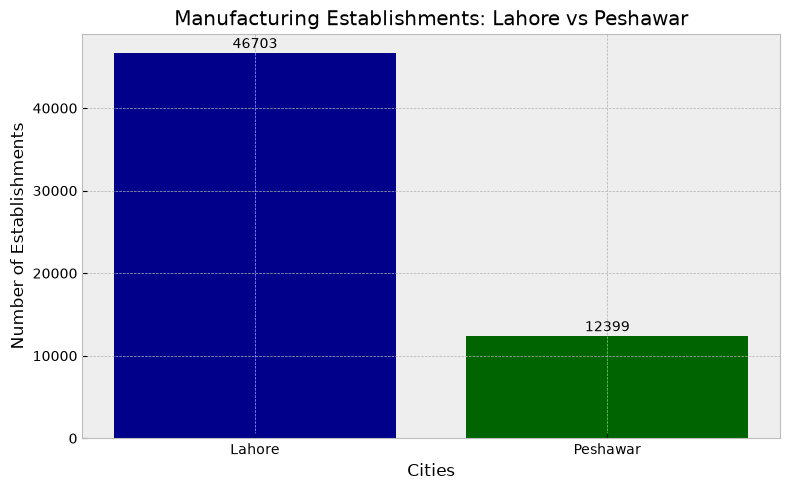

In [20]:
# Visualization of manufacturing establishments in Lahore and Peshawar

plt.figure(figsize=(8, 5))

bars = plt.bar(
    compare_manufact["City"],
    compare_manufact["Establishments"],
    color=["darkblue", "darkgreen"]
)

plt.bar_label(bars, padding=1)

plt.title("Manufacturing Establishments: Lahore vs Peshawar")
plt.xlabel("Cities")
plt.ylabel("Number of Establishments")

plt.tight_layout()
plt.show()

In [21]:
# Manufacturing Sector key insights

# 1. Establishments: Lahore has 46,703 manufacturing establishments,
# whereas Peshawar has 12,399. This is approximately 3.8 times higher.

# 2. Workforce: Lahore has 296,298 manufacturing workers,
# whereas Peshawar has 50,816. This is approximately 5.8 times higher.

# 3. General observation: The manufacturing sector of Lahore is bigger
# than that of Peshawar, both in terms of establishments and workforce.

# 4. Nevertheless, these figures alone do not give reasons
# why such differences exist.

In [22]:
# Calculate total workforce of each city

total_workforce = df.groupby("City")["Workforce"].sum()

total_workforce.sort_values(ascending=False)

City
Lahore       2014908
Karachi      1567422
Islamabad     621514
Peshawar      587659
Quetta        438882
Name: Workforce, dtype: int64

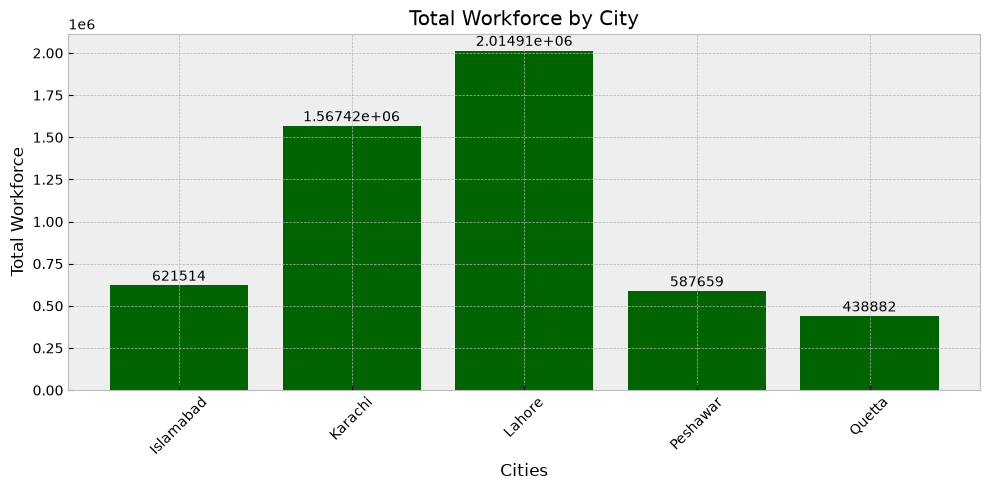

In [23]:
# Visualization of total workforce by city

plt.figure(figsize=(10, 5))

bars = plt.bar(
    total_workforce.index,
    total_workforce.values,
    color="darkgreen"
)

plt.bar_label(bars, padding=1)

plt.title("Total Workforce by City")
plt.xlabel("Cities")
plt.ylabel("Total Workforce")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [24]:
# Calculate total establishments of each city

total_establishments = df.groupby("City")["Establishments"].sum()

total_establishments.sort_values(ascending=False)

City
Lahore       429891
Karachi      341682
Peshawar     116022
Islamabad     86154
Quetta        84231
Name: Establishments, dtype: int64

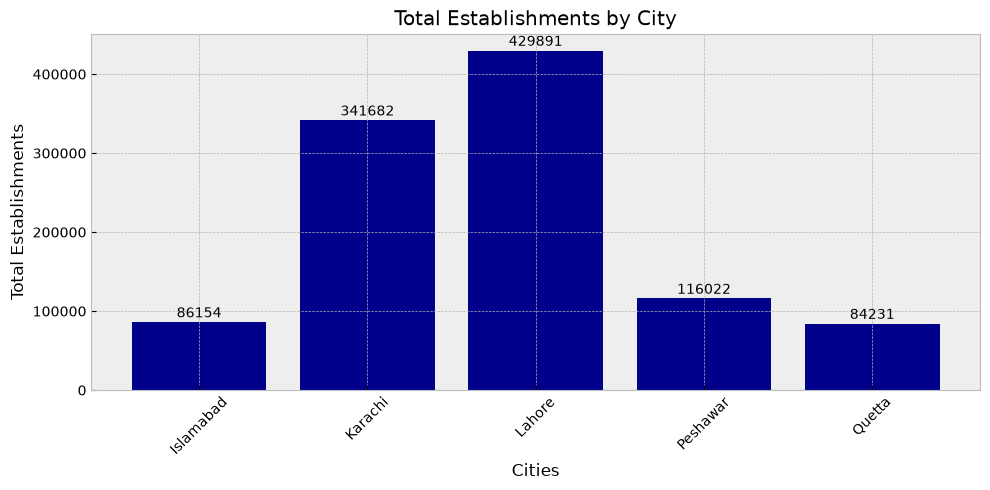

In [25]:
# Visualization of total establishments by city

plt.figure(figsize=(10, 5))

bars = plt.bar(
    total_establishments.index,
    total_establishments.values,
    color="darkblue"
)

plt.bar_label(bars, padding=1)

plt.title("Total Establishments by City")
plt.xlabel("Cities")
plt.ylabel("Total Establishments")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()